### Diversity, Sovereignty and Vulnerability in Brazilian DNS Infrastructure

Provider Concentration and Sectoral Dependence
Which are the most dominant DNS providers in the dataset?
- Gráfico: Pareto chart (top providers)

What is the market share of major providers per sector?
- Gráfico: heatmap (sector × provider)
- Are there sectors that are overly dependent on one or two providers?


In [33]:
import pandas as pd
import os
import seaborn as sns

BASE_DATA = r"..\src\eu_analysis_data.csv"
base_data = pd.read_csv(BASE_DATA, sep=';', encoding='utf-8')
display(base_data.sort_values(by='revenue', ascending=False).head(5))

print(base_data.dtypes)


# change name of colt tech to justo colt

base_data['dominant_provider'] = base_data['dominant_provider'].replace('Colt Technology Services', 'Colt')

PLOT_FONT_SIZE = 12


,company_name,country_name,sector_primary,revenue,earnings,total_assets,domain,num_ns,num_asn,asn_list,...,dominant_provider_country,dominant_provider_asn,only_one_provider,distinct_asns,distinct_countries,country_list,provider_list,num_ns_in_eu,num_ns_foreign,infra_type
0,volkswagen,DE,Capital Goods and Industrial Equipment,351872611960,15798600000,692049000000.0,vw.com,2.0,2,"['3458', '55239']",...,US,3458,True,2.0,1,['US'],['Volkswagen Group'],0.0,2,100% estrangeira
1,exor,NL,Financial Sector,223206888765,10125000000,44184500000.0,exor.com,4.0,2,"['197019', '8220']",...,GB,8220,False,2.0,2,"['CZ', 'GB']","['Colt Technology Services', 'WEDOS']",0.0,4,100% estrangeira
2,totalenergies,FR,Oil and Chemical,191626000000,27747000000,291057000000.0,totalenergies.com,4.0,1,['21070'],...,FR,21070,True,1.0,1,['FR'],['TotalEnergies'],0.0,4,100% estrangeira
3,deutsche telekom,DE,Technology and Telecommunications,179760078566,26307300000,330108000000.0,telekom.com,4.0,1,['3320'],...,DE,3320,True,1.0,1,['DE'],['Deutsche Telekom'],0.0,4,100% estrangeira
4,mercedes-benz,DE,Capital Goods and Industrial Equipment,153928068631,14152700000,282791000000.0,mbusa.com,4.0,3,"['141760', '31399', '32611']",...,DE,31399,True,3.0,1,['DE'],['Mercedes-Benz Group'],0.0,4,100% estrangeira


company_name                  object
country_name                  object
sector_primary                object
revenue                        int64
earnings                       int64
total_assets                  object
domain                        object
num_ns                       float64
num_asn                       object
asn_list                      object
num_country                   object
countries_used                object
pct_national_ns               object
only_foreign_ns               object
has_ipv4_ns                   object
has_ipv6_ns                   object
dual_stack                    object
dominant_provider             object
dominant_provider_country     object
dominant_provider_asn         object
only_one_provider             object
distinct_asns                float64
distinct_countries            object
country_list                  object
provider_list                 object
num_ns_in_eu                 float64
num_ns_foreign                object
i

### Provider Concentration and Sectoral Dependence
#### Which are the most dominant DNS providers in the dataset?
→ Gráfico: Pareto chart (top providers)
#### What is the market share of major providers per sector?
→ Gráfico: heatmap (sector × provider)
#### Are there sectors that are overly dependent on one or two providers?
→ Gráfico: stacked bar chart

In [34]:
import pandas as pd

# Número de domínios por setor
domains_by_sector = base_data.groupby('sector_primary').size().reset_index(name='Domain_Count')

# Receita total por setor
revenue_by_sector = base_data.groupby('sector_primary')['revenue'].sum().reset_index(name='Total_Revenue')

# Junta as duas informações
sector_summary = pd.merge(domains_by_sector, revenue_by_sector, on='sector_primary')

# Ordena pelo número de domínios (Domain_Count) em ordem decrescente
sector_summary = sector_summary.sort_values(by='Domain_Count', ascending=False).reset_index(drop=True)

# Converte a receita total para milhões de dolares
sector_summary['Total_Revenue'] = (sector_summary['Total_Revenue'] / 1_000_000).round(1)

sector_summary = sector_summary.rename(columns={
    'sector_primary': 'Primary Sector',
    'Domain_Count': 'Main Domain Count',
    'Total_Revenue': 'Total Revenue in Millions (USD)'
})

# Salva em CSV
sector_summary.to_csv('./tables/eu_sector_domain_and_revenue_summary.csv', sep=';', index=False, encoding='utf-8')

display(sector_summary)


,Primary Sector,Main Domain Count,Total Revenue in Millions (USD)
0,Capital Goods and Industrial Equipment,193,2172778.5
1,Technology and Telecommunications,140,892451.3
2,Financial Sector,130,1583661.5
3,Real Estate and Construction,88,598634.9
4,Wholesale and Retail,84,875991.0
5,Health and Healthcare Services,80,477643.5
6,Others,69,251878.9
7,Energy,53,758995.0
8,Transport Logistics and Logistic Services,45,483279.5
9,Food and Beverages,43,251981.6


C:\Users\fsbertoglio\AppData\Local\Temp\ipykernel_7104\2554303256.py:31: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(
C:\Users\fsbertoglio\AppData\Local\Temp\ipykernel_7104\2554303256.py:44: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(


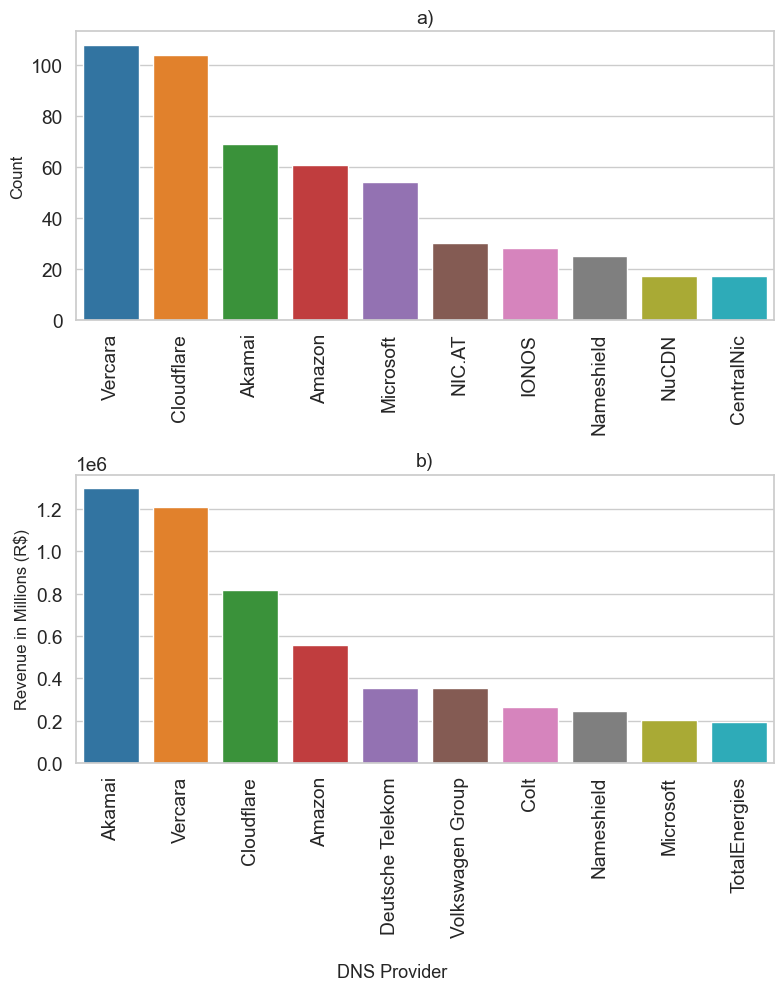

In [26]:
# #### Which are the most dominant DNS providers in the dataset?
# → Gráfico: Pareto chart (top providers)


import matplotlib.pyplot as plt
import seaborn as sns

# top providers by concentrated count
top_providers = base_data['dominant_provider'].value_counts().head(10)
top_providers = top_providers.sort_values(ascending=False)
top_providers = top_providers.reset_index()
top_providers.columns = ['dominant_provider', 'count']

# Save top providers by count to CSV
top_providers.to_csv('./tables/eu_top_dns_providers_by_count.csv', sep=';', encoding='utf-8', index=False)


# top providers by concentrated revenue
top_providers_revenue = base_data.groupby('dominant_provider')['revenue'].sum().reset_index()
top_providers_revenue = top_providers_revenue.sort_values(by='revenue', ascending=False).head(10)
top_providers_revenue['revenue'] = top_providers_revenue['revenue'] / 1_000_000  # Convert to millions

# Save top providers by revenue to CSV
top_providers_revenue.to_csv('./tables/eu_top_dns_providers_by_revenue.csv', sep=';', encoding='utf-8', index=False)



fig, axes = plt.subplots(2, 1, figsize=(8, 10))

# Barplot: Top DNS Providers by Count
sns.barplot(
    data=top_providers,
    x='dominant_provider',
    y='count',
    palette='tab10',
    ax=axes[0]
)
axes[0].set_title('a)', fontsize=14)
axes[0].set_xlabel('')  # Hide xlabel
axes[0].set_ylabel('Count')
axes[0].tick_params(axis='x', rotation=90)

# Barplot: Top DNS Providers by Revenue
sns.barplot(
    data=top_providers_revenue,
    x='dominant_provider',
    y='revenue',
    palette='tab10',
    ax=axes[1]
)
axes[1].set_title('b)', fontsize=14)
axes[1].set_xlabel('')  # Hide xlabel
axes[1].set_ylabel('Revenue in Millions (R$)')
axes[1].tick_params(axis='x', rotation=90)

fig.supxlabel('DNS Provider', fontsize=13)
plt.tight_layout()
plt.show()




In [35]:
# Herfindahl-Hirschman Index

import pandas as pd

# Supondo que base_data já está carregado e tem as colunas 'dominant_provider', 'sector_primary' e 'revenue'

# Calcule a receita total por setor
total_revenue_by_sector = base_data.groupby('sector_primary')['revenue'].sum()

# Calcule a receita por provedor e setor
provider_sector_revenue = base_data.groupby(['dominant_provider', 'sector_primary'])['revenue'].sum().reset_index()

# Calcule o marketshare (em %) de cada provedor em cada setor
provider_sector_revenue['marketshare'] = provider_sector_revenue.apply(
    lambda row: (row['revenue'] / total_revenue_by_sector[row['sector_primary']]) * 100
    if total_revenue_by_sector[row['sector_primary']] > 0 else 0,
    axis=1
)

# Crie o DataFrame pivô: linhas = provedores, colunas = setores, valores = marketshare
marketshare_df = provider_sector_revenue.pivot_table(
    index='dominant_provider',
    columns='sector_primary',
    values='marketshare',
    fill_value=0
)
# Opcional: arredonde para 2 casas decimais
marketshare_df = marketshare_df.round(2)

# Exiba o resultado
display(marketshare_df)

# Calcule o HHI para cada setor (coluna)
hhi_by_sector = (marketshare_df ** 2).sum(axis=0)

display(hhi_by_sector)

# Opcional: converta para DataFrame para facilitar o plot
hhi_df = hhi_by_sector.reset_index()
hhi_df.columns = ['Sector', 'HHI']

# Salve o DataFrame de marketshare por provedor e setor em CSV
hhi_df.to_csv('./tables/eu_provider_sector_marketshare_by_revenue.csv', sep=';', encoding='utf-8')



# Calcule o total de empresas por setor
total_count_by_sector = base_data.groupby('sector_primary').size()

# Calcule o número de empresas por provedor e setor
provider_sector_count = base_data.groupby(['dominant_provider', 'sector_primary']).size().reset_index(name='count')

# Calcule o marketshare (em %) de cada provedor em cada setor (por quantidade)
provider_sector_count['marketshare'] = provider_sector_count.apply(
    lambda row: (row['count'] / total_count_by_sector[row['sector_primary']]) * 100
    if total_count_by_sector[row['sector_primary']] > 0 else 0,
    axis=1
)

# Crie o DataFrame pivô: linhas = provedores, colunas = setores, valores = marketshare (por quantidade)
marketshare_count_df = provider_sector_count.pivot_table(
    index='dominant_provider',
    columns='sector_primary',
    values='marketshare',
    fill_value=0
)
marketshare_count_df = marketshare_count_df.round(2)

display(marketshare_count_df)

# Calcule o HHI para cada setor (coluna) usando marketshare por quantidade
hhi_count_by_sector = (marketshare_count_df ** 2).sum(axis=0)

display(hhi_count_by_sector)

# Opcional: converta para DataFrame para facilitar o plot
hhi_count_df = hhi_count_by_sector.reset_index()
hhi_count_df.columns = ['Sector', 'HHI_Count']

# Salve o DataFrame de marketshare por provedor e setor em CSV (por quantidade)
hhi_count_df.to_csv('./tables/eu_provider_sector_marketshare_by_count.csv', sep=';', encoding='utf-8')



# Combine as duas métricas HHI em uma única tabela
hhi_merged = pd.merge(
    hhi_count_df,
    hhi_df,
    on='Sector',
    how='outer',
    suffixes=('_count', '_revenue')
)
hhi_merged = hhi_merged.rename(columns={
    'Sector': 'sector_primary',
    'HHI_Count': 'hhi_count',
    'HHI': 'hhi_revenue'
})

import pandas as pd

# ... (código anterior mantido, até a parte da tabela combinada)

# --- Cálculo do HHI geral por receita ---

# Receita total de todas as empresas (soma de todos os setores)
total_revenue_all = base_data['revenue'].sum()

# Receita total por provedor em todos os setores
provider_total_revenue = base_data.groupby('dominant_provider')['revenue'].sum()

# Calcula o marketshare geral de cada provedor (em %)
provider_total_marketshare = (provider_total_revenue / total_revenue_all) * 100

# Calcula o HHI geral por receita
hhi_revenue_overall = (provider_total_marketshare ** 2).sum()

print(f"HHI geral por receita: {hhi_revenue_overall:.2f}")

# --- Cálculo do HHI geral por quantidade de empresas ---

# Total de empresas (todos os setores)
total_count_all = len(base_data)

# Total de empresas por provedor (todos os setores)
provider_total_count = base_data.groupby('dominant_provider').size()

# Calcula o marketshare geral de cada provedor (em %)
provider_count_marketshare = (provider_total_count / total_count_all) * 100

# Calcula o HHI geral por quantidade
hhi_count_overall = (provider_count_marketshare ** 2).sum()

print(f"HHI geral por quantidade: {hhi_count_overall:.2f}")

# --- Inclui os valores gerais na tabela final ---

# Cria uma linha para o HHI geral
hhi_overall_row = pd.DataFrame([{
    'sector_primary': 'Total',
    'hhi_count': hhi_count_overall,
    'hhi_revenue': hhi_revenue_overall
}])

# Adiciona à tabela existente
hhi_merged_with_overall = pd.concat([hhi_merged, hhi_overall_row], ignore_index=True)

display(hhi_merged_with_overall)

# Salva o resultado com a linha "ALL"
hhi_merged_with_overall.to_csv('./tables/eu_sector_hhi_summary.csv', sep=';', encoding='utf-8', index=False)


sector_primary,Agribusiness,Capital Goods and Industrial Equipment,Energy,Financial Sector,Food and Beverages,Health and Healthcare Services,Oil and Chemical,Others,Real Estate and Construction,Sanitation and Environment,Steel Mining and Metallurgy,Technology and Telecommunications,Transport Logistics and Logistic Services,Wholesale and Retail
dominant_provider,,,,,,,,,,,,,,
AAG,0.0,0.41,0.00,0.0,0.0,0.00,0.0,0.00,0.00,0.0,0.00,0.00,0.0,0.00
ADMIN ACENS ES,0.0,0.03,0.00,0.0,0.0,0.00,0.0,0.00,0.82,0.0,0.00,0.00,0.0,0.00
ALBACOM-MNT,0.0,0.04,0.00,0.0,0.0,0.00,0.0,0.00,0.00,0.0,0.00,0.00,0.0,0.00
ALIOR-MNT,0.0,0.00,0.00,0.1,0.0,0.00,0.0,0.00,0.00,0.0,0.00,0.00,0.0,0.00
ANYCAST-MNT,0.0,0.00,0.00,0.2,0.0,0.21,0.0,0.00,0.00,0.0,0.00,0.08,0.0,0.35
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
indra_sistemas,0.0,0.00,0.00,0.0,0.0,0.00,0.0,0.00,0.00,0.0,0.00,0.71,0.0,0.00
nmm-mnt,0.0,0.00,0.00,0.0,0.0,0.00,0.0,0.00,0.00,0.0,0.51,0.00,0.0,0.00
pt-ren-1-mnt,0.0,0.00,0.16,0.0,0.0,0.00,0.0,0.00,0.00,0.0,0.00,0.00,0.0,0.00


sector_primary
Agribusiness                                 7769.0810
Capital Goods and Industrial Equipment        929.5122
Energy                                        800.7089
Financial Sector                             1221.7675
Food and Beverages                           3758.8670
Health and Healthcare Services                857.1998
Oil and Chemical                             1395.1607
Others                                       1642.9770
Real Estate and Construction                  827.9712
Sanitation and Environment                   5573.0985
Steel Mining and Metallurgy                  1121.7962
Technology and Telecommunications             711.8741
Transport Logistics and Logistic Services    1844.5612
Wholesale and Retail                         2566.4456
dtype: float64

sector_primary,Agribusiness,Capital Goods and Industrial Equipment,Energy,Financial Sector,Food and Beverages,Health and Healthcare Services,Oil and Chemical,Others,Real Estate and Construction,Sanitation and Environment,Steel Mining and Metallurgy,Technology and Telecommunications,Transport Logistics and Logistic Services,Wholesale and Retail
dominant_provider,,,,,,,,,,,,,,
AAG,0.0,0.52,0.00,0.00,0.0,0.00,0.0,0.00,0.00,0.0,0.00,0.00,0.0,0.00
ADMIN ACENS ES,0.0,0.52,0.00,0.00,0.0,0.00,0.0,0.00,1.14,0.0,0.00,0.00,0.0,0.00
ALBACOM-MNT,0.0,0.52,0.00,0.00,0.0,0.00,0.0,0.00,0.00,0.0,0.00,0.00,0.0,0.00
ALIOR-MNT,0.0,0.00,0.00,0.77,0.0,0.00,0.0,0.00,0.00,0.0,0.00,0.00,0.0,0.00
ANYCAST-MNT,0.0,0.00,0.00,0.77,0.0,1.25,0.0,0.00,0.00,0.0,0.00,0.71,0.0,2.38
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
indra_sistemas,0.0,0.00,0.00,0.00,0.0,0.00,0.0,0.00,0.00,0.0,0.00,0.71,0.0,0.00
nmm-mnt,0.0,0.00,0.00,0.00,0.0,0.00,0.0,0.00,0.00,0.0,3.45,0.00,0.0,0.00
pt-ren-1-mnt,0.0,0.00,1.89,0.00,0.0,0.00,0.0,0.00,0.00,0.0,0.00,0.00,0.0,0.00


sector_primary
Agribusiness                                 2221.7778
Capital Goods and Industrial Equipment        428.0073
Energy                                        338.4810
Financial Sector                              778.9634
Food and Beverages                           1281.9008
Health and Healthcare Services                484.3750
Oil and Chemical                              729.5506
Others                                        753.8119
Real Estate and Construction                  506.4386
Sanitation and Environment                   2500.0000
Steel Mining and Metallurgy                   606.5447
Technology and Telecommunications             389.3766
Transport Logistics and Logistic Services     513.3977
Wholesale and Retail                          895.4513
dtype: float64

HHI geral por receita: 533.58
HHI geral por quantidade: 395.23


,sector_primary,hhi_count,hhi_revenue
0,Agribusiness,2221.7778,7769.081000
1,Capital Goods and Industrial Equipment,428.0073,929.512200
2,Energy,338.4810,800.708900
3,Financial Sector,778.9634,1221.767500
4,Food and Beverages,1281.9008,3758.867000
5,Health and Healthcare Services,484.3750,857.199800
6,Oil and Chemical,729.5506,1395.160700
7,Others,753.8119,1642.977000
8,Real Estate and Construction,506.4386,827.971200
9,Sanitation and Environment,2500.0000,5573.098500


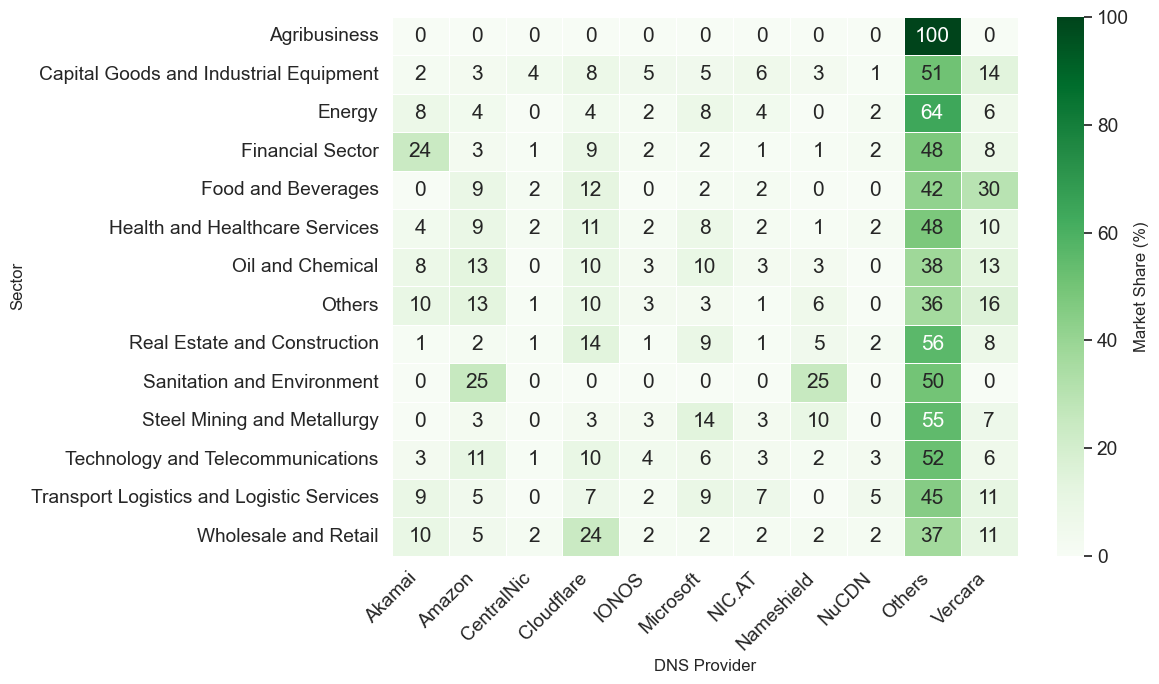

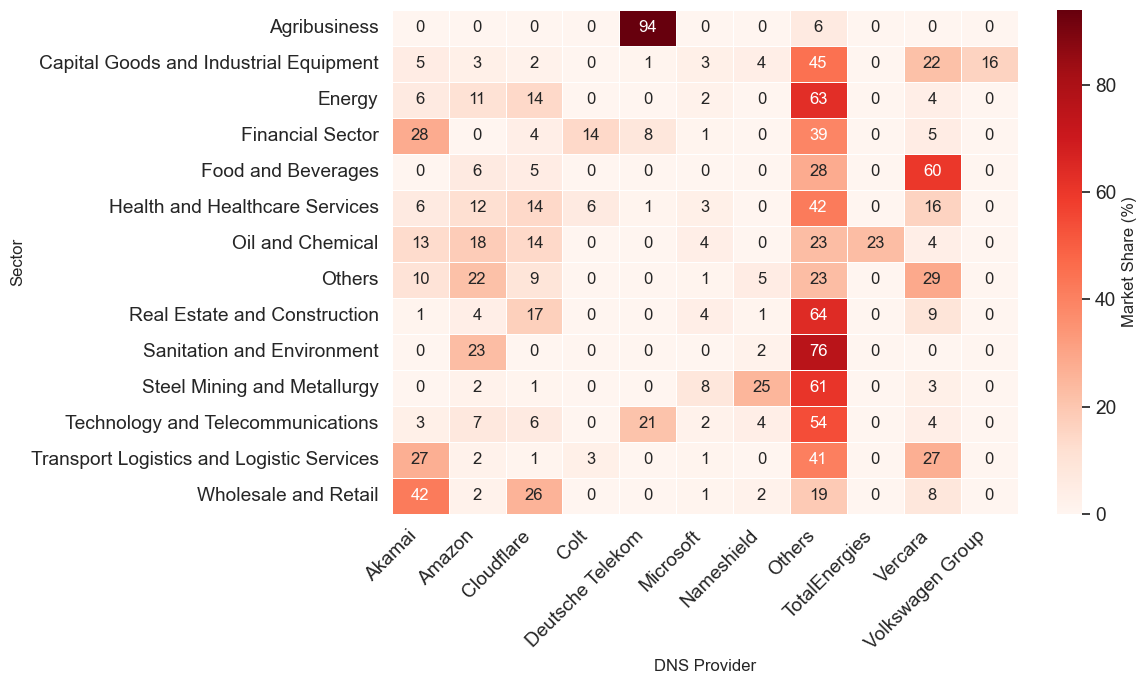

In [28]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

pivot_pct_count = pd.read_csv('./tables/eu_sector_provider_market_share_by_count.csv', sep=';', index_col='Sector')
pivot_pct_revenue = pd.read_csv('./tables/eu_sector_provider_market_share_by_revenue.csv', sep=';', index_col='Sector')

sns.set(style="whitegrid", font_scale=1.25, rc={"axes.labelsize": 12, "axes.titlesize": 13})

# Gráfico 1: Heatmap por Contagem de Domínios
plt.figure(figsize=(12, 7))
sns.heatmap(
    pivot_pct_count,
    annot=True,
    fmt='.0f',
    cmap="Greens",
    linewidths=0.5,
    cbar_kws={'label': 'Market Share (%)'}
)
plt.ylabel('Sector')
plt.xlabel('DNS Provider')
plt.xticks(rotation=45, ha='right')
plt.rcParams['font.size'] = PLOT_FONT_SIZE
plt.tight_layout()
plt.show()

# Gráfico 2: Heatmap por Receita Agregada
plt.figure(figsize=(12, 7))
sns.heatmap(
    pivot_pct_revenue,
    annot=True,
    fmt='.0f',
    cmap="Reds",
    linewidths=0.5,
    cbar_kws={'label': 'Market Share (%)'}
)
plt.ylabel('Sector')
plt.xlabel('DNS Provider')
plt.xticks(rotation=45, ha='right')
plt.rcParams['font.size'] = PLOT_FONT_SIZE
plt.tight_layout()
plt.show()


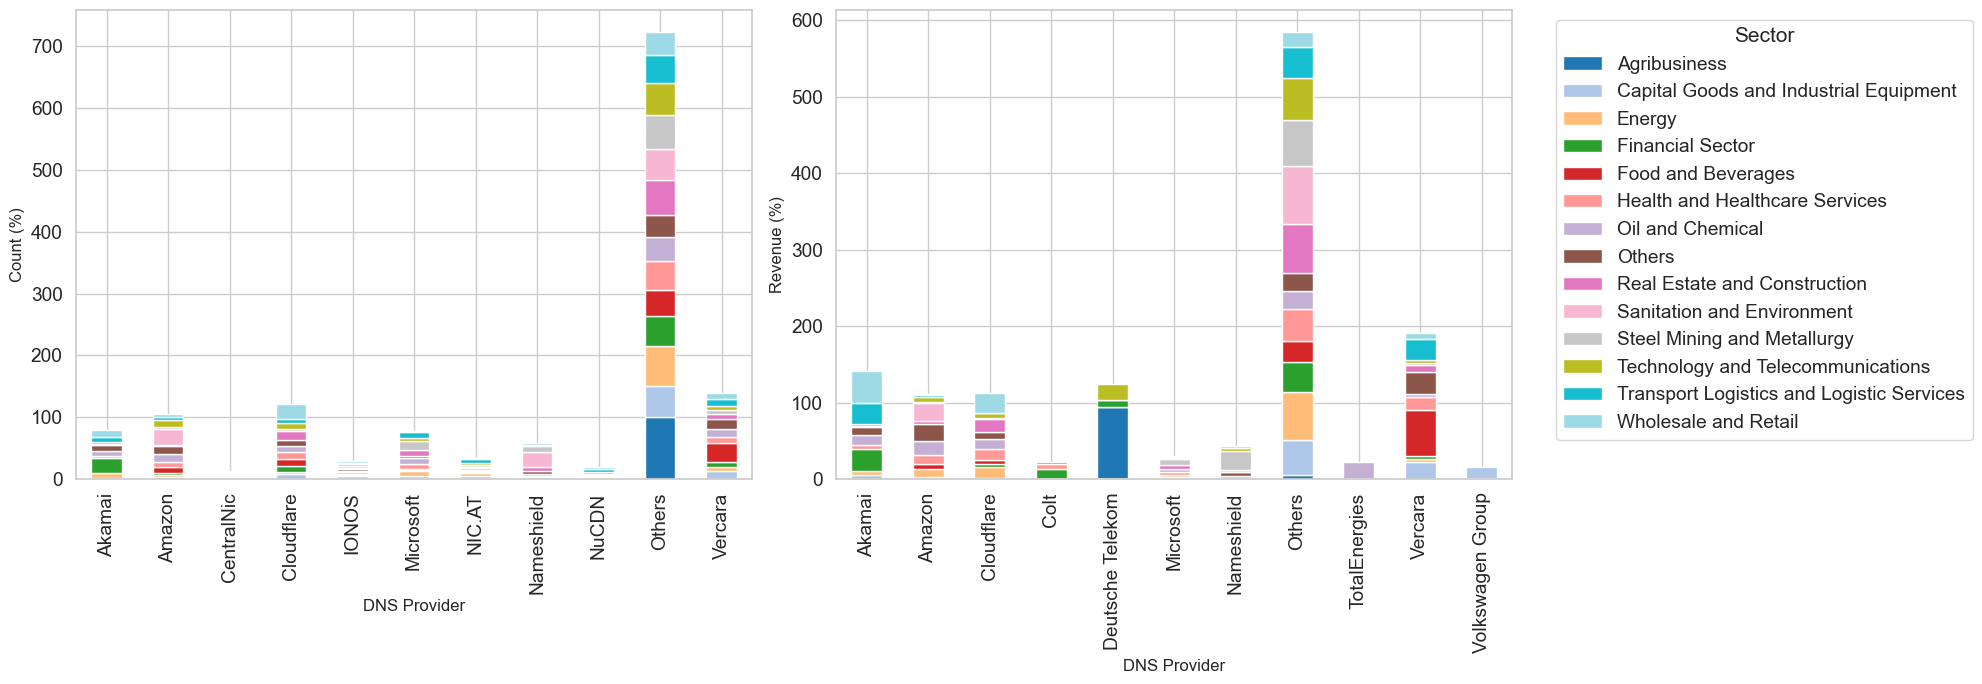

In [29]:
# Load sector-provider pivot data from file before plotting
sector_provider_pivot = pd.read_csv('./tables/eu_sector_provider_market_share_by_count.csv', sep=';', index_col='Sector')
sector_provider_pivot = pd.read_csv('./tables/eu_sector_provider_market_share_by_revenue.csv', sep=';', index_col='Sector')

fig, axes = plt.subplots(1, 2, figsize=(20, 7))

# By Count
pivot_pct_count.T.plot(
    kind='bar',
    stacked=True,
    ax=axes[0],
    colormap='tab20'
)
axes[0].set_xlabel('DNS Provider')
axes[0].set_ylabel('Count (%)')
axes[0].legend_.remove()
axes[0].tick_params(axis='x', rotation=90)

# By Revenue
pivot_pct_revenue.T.plot(
    kind='bar',
    stacked=True,
    ax=axes[1],
    colormap='tab20'
)
axes[1].set_xlabel('DNS Provider')
axes[1].set_ylabel('Revenue (%)')
axes[1].legend(title='Sector', bbox_to_anchor=(1.05, 1), loc='upper left')
axes[1].tick_params(axis='x', rotation=90)

plt.tight_layout()
plt.show()

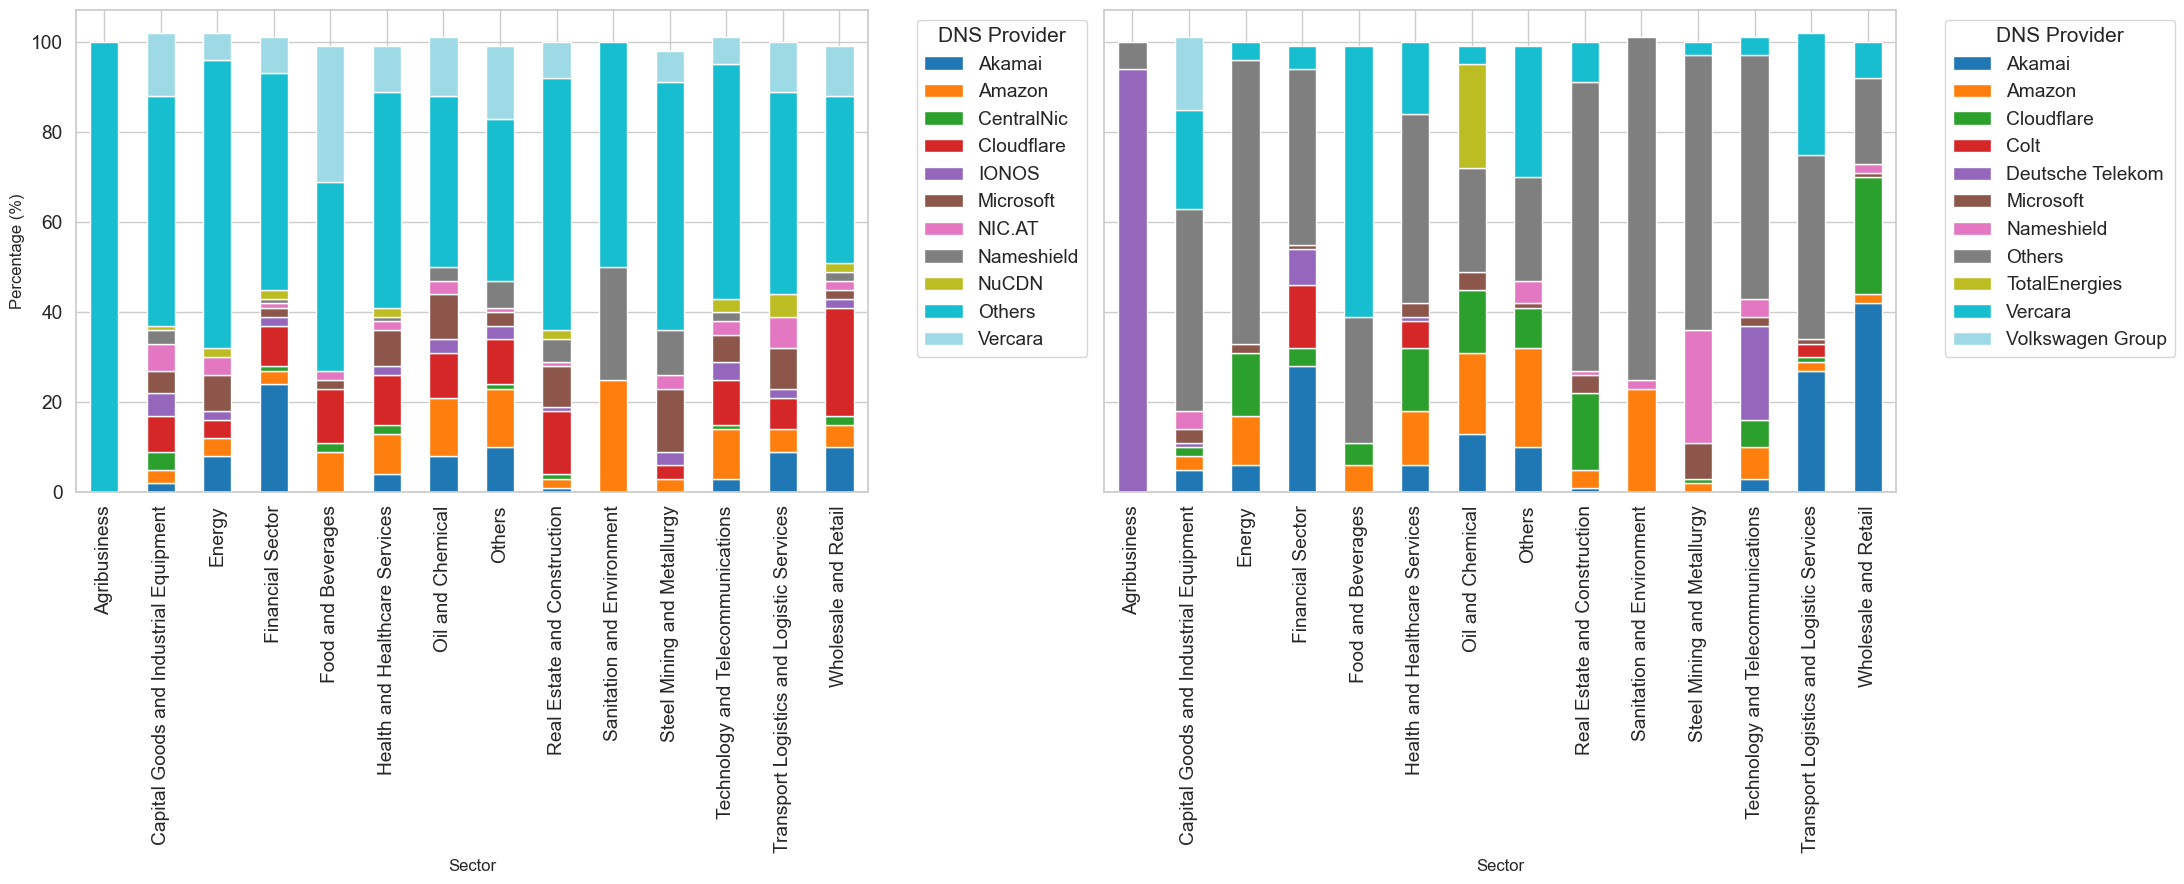

In [30]:
import pandas as pd

# #### Market Share of Major DNS Providers per Sector (by Count and by Revenue)

# --- By Count ---
top_providers_count = base_data['dominant_provider'].value_counts().nlargest(10).index.tolist()
sector_provider_count = base_data.groupby(['sector_primary', 'dominant_provider']).size().reset_index(name='count')
sector_provider_count['provider_group'] = sector_provider_count['dominant_provider'].where(
    sector_provider_count['dominant_provider'].isin(top_providers_count), other='Others'
)
sector_provider_grouped_count = sector_provider_count.groupby(['sector_primary', 'provider_group'])['count'].sum().reset_index()
pivot_count = sector_provider_grouped_count.pivot(index='sector_primary', columns='provider_group', values='count').fillna(0)
pivot_pct_count = pivot_count.div(pivot_count.sum(axis=1), axis=0) * 100
pivot_pct_count = pivot_pct_count.round(0).reset_index().rename(columns={'sector_primary': 'Sector'}).set_index('Sector')
pivot_pct_count.to_csv(r'./tables/eu_sector_provider_market_share_by_count.csv', sep=';', encoding='utf-8')

# --- By Revenue ---
top_providers_revenue = base_data.groupby('dominant_provider')['revenue'].sum().nlargest(10).index.tolist()
sector_provider_revenue = base_data.groupby(['sector_primary', 'dominant_provider'])['revenue'].sum().reset_index()
sector_provider_revenue['provider_group'] = sector_provider_revenue['dominant_provider'].where(
    sector_provider_revenue['dominant_provider'].isin(top_providers_revenue), other='Others'
)
sector_provider_grouped_revenue = sector_provider_revenue.groupby(['sector_primary', 'provider_group'])['revenue'].sum().reset_index()
pivot_revenue = sector_provider_grouped_revenue.pivot(index='sector_primary', columns='provider_group', values='revenue').fillna(0)
pivot_pct_revenue = pivot_revenue.div(pivot_revenue.sum(axis=1), axis=0) * 100
pivot_pct_revenue = pivot_pct_revenue.round(0).reset_index().rename(columns={'sector_primary': 'Sector'}).set_index('Sector')
pivot_pct_revenue.to_csv(r'./tables/eu_sector_provider_market_share_by_revenue.csv', sep=';', encoding='utf-8')


# --- Load data from saved CSVs ---
import matplotlib.pyplot as plt

# Load percentage by count and by revenue
pivot_pct_count = pd.read_csv('./tables/eu_sector_provider_market_share_by_count.csv', sep=';', index_col='Sector')
pivot_pct_revenue = pd.read_csv('./tables/eu_sector_provider_market_share_by_revenue.csv', sep=';', index_col='Sector')

# --- Plot by Count and by Revenue side by side ---
fig, axes = plt.subplots(1, 2, figsize=(22, 9), sharey=True)

# Plot by Count
pivot_pct_count.plot(
    kind='bar',
    stacked=True,
    cmap='tab20',
    ax=axes[0]
)

axes[0].set_xlabel('Sector', fontsize=12)
axes[0].set_ylabel('Percentage (%)', fontsize=12)
axes[0].legend(title='DNS Provider', bbox_to_anchor=(1.05, 1), loc='upper left')
axes[0].tick_params(axis='x', rotation=90)

# Plot by Revenue
pivot_pct_revenue.plot(
    kind='bar',
    stacked=True,
    cmap='tab20',
    ax=axes[1]
)
axes[1].set_xlabel('Sector', fontsize=12)
axes[1].set_ylabel('')
axes[1].legend(title='DNS Provider', bbox_to_anchor=(1.05, 1), loc='upper left')
axes[1].tick_params(axis='x', rotation=90)

plt.tight_layout()
plt.show()


In [31]:
import pandas as pd

# Carregar o CSV original
df = base_data.copy()

# Agrupar receitas por setor e provedor dominante
grouped = df.groupby(['sector_primary', 'dominant_provider'])['revenue'].sum().reset_index()

# Função para obter top 10 por setor, marcando os demais como "Others"
def top10_and_others(group):
    # Ordena do maior para o menor
    group = group.sort_values(by='revenue', ascending=False)
    # Se tiver mais de 10 provedores, top 10 + soma do resto em "Others"
    if len(group) > 10:
        top = group.iloc[:10]
        others_sum = group.iloc[10:]['revenue'].sum()
        # Cria linha "Others"
        others_row = pd.DataFrame({
            'sector_primary': [group['sector_primary'].iloc[0]],
            'dominant_provider': ['Others'],
            'revenue': [others_sum]/1_000
        })
        result = pd.concat([top, others_row], ignore_index=True)
    else:
        result = group
    return result

# Aplicar a função para cada setor
result_df = grouped.groupby('sector_primary', group_keys=False).apply(top10_and_others)

# Renomear as colunas para ficar igual ao exemplo desejado
result_df = result_df.rename(columns={
    'sector_primary': 'Sector',
    'dominant_provider': 'Provider',
    'revenue': 'Revenue'
})

# (Opcional) Ordenar resultado por setor, decrescentemente por receita
result_df = result_df.sort_values(['Sector', 'Revenue'], ascending=[True, False])

# Salvar em CSV
result_df.to_csv('./tables/eu_top10_providers_by_sector_revenue.csv', sep=';', index=False)

print(result_df)



####################################################
df = base_data.copy()

# Agrupar por setor e provedor, contando domínios distintos
grouped = (
    df.groupby(['sector_primary', 'dominant_provider'])
    .size()
    .reset_index(name='domain_count')
)

grouped.to_csv('./tempp', sep=';')

# Função para obter top 10 por setor e agrupar os demais em "Others"
def top10_and_others_count(group):
    group = group.sort_values(by='domain_count', ascending=False)
    if len(group) > 10:
        top = group.iloc[:10]
        others_sum = group.iloc[10:]['domain_count'].sum()
        others_row = pd.DataFrame({
            'sector_primary': [group['sector_primary'].iloc[0]],
            'dominant_provider': ['Others'],
            'domain_count': [others_sum]
        })
        result = pd.concat([top, others_row], ignore_index=True)
    else:
        result = group
    return result

# Aplicar função para cada setor
result_count_df = grouped.groupby('sector_primary', group_keys=False).apply(top10_and_others_count)

# Renomear colunas para o formato desejado
result_count_df = result_count_df.rename(columns={
    'sector_primary': 'Sector',
    'dominant_provider': 'Provider',
    'domain_count': 'Count'
})

# Ordenar resultado
result_count_df = result_count_df.sort_values(['Sector', 'Count'], ascending=[True, False])

# Salvar resultado
result_count_df.to_csv('./tables/eu_top10_providers_by_sector_count.csv', sep=';', index=False)

print(result_count_df)

print(result_df)

KeyError: 'sector_primary'

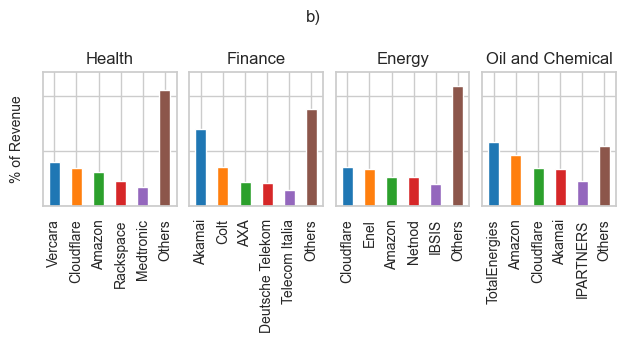

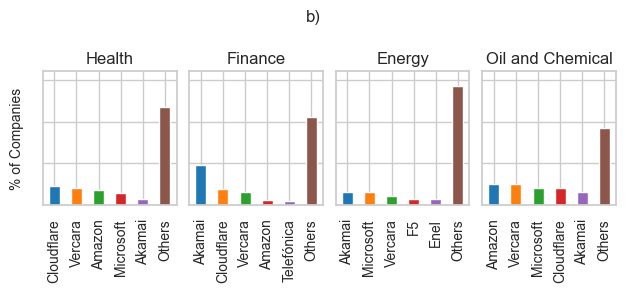

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt

desired_sectors = [
    'Health and Healthcare Services',
    'Financial Sector',
    'Energy',
    'Oil and Chemical'
]

# Nomes para mostrar nos gráficos:
display_names = [
    'Health',
    'Finance',
    'Energy',
    'Oil and Chemical'
]

# Parâmetro padrão ABNT
textwidth_cm = 16
textwidth_inch = textwidth_cm / 2.54
font_size = 10

n_plots = len(desired_sectors)
square_size = textwidth_inch / n_plots
hspace = 0.15
fig_width = textwidth_inch
fig_height = square_size + 1.5

# --------- Revenue ----------
df = pd.read_csv('./tables/eu_top10_providers_by_sector_revenue.csv', sep=';')
df = df[df['Sector'].isin(desired_sectors) & (df['Sector'] != 'Total')].copy()
df['TotalRevenue'] = df.groupby('Sector')['Revenue'].transform('sum')
df['Pct'] = df['Revenue'] / df['TotalRevenue'] * 100
df_top5 = df[df['Provider'] != 'Others'].copy()
df_top5['Rank'] = df_top5.groupby('Sector')['Revenue'].rank(method='first', ascending=False)
df_top5 = df_top5[df_top5['Rank'] <= 5]

plot_df = []
for sector in desired_sectors:
    sector_df = df[df['Sector'] == sector].copy()
    sector_top5 = df_top5[df_top5['Sector'] == sector].sort_values('Pct', ascending=False)
    providers = list(sector_top5['Provider'])
    pct_values = list(sector_top5['Pct'])
    while len(providers) < 5:
        providers.append('(empty)')
        pct_values.append(0)
    top5_names = set(sector_top5['Provider'])
    others_pct = sector_df[~sector_df['Provider'].isin(top5_names)]['Pct'].sum()
    providers.append('Others')
    pct_values.append(others_pct)
    plot_df.append((providers, pct_values))

ymax = max([max(pct_values) for providers, pct_values in plot_df])
ymax = min(100, ymax * 1.12)

fig, axes = plt.subplots(1, n_plots, figsize=(fig_width, fig_height), sharey=True)
if n_plots == 1:
    axes = [axes]

for i, (ax, (providers, pct_values)) in enumerate(zip(axes, plot_df)):
    bars = ax.bar(providers, pct_values, color=plt.cm.tab10.colors[:6], width=0.5)
    ax.set_title(display_names[i], fontsize=font_size + 2)  # <-- Título correto
    if i == 0:
        ax.set_ylabel("% of Revenue", fontsize=font_size)
    else:
        ax.set_ylabel("")
        ax.set_yticklabels([])
    ax.set_ylim(0, ymax)
    ax.tick_params(axis='x', rotation=90, labelsize=font_size)
    ax.tick_params(axis='y', labelsize=font_size)
    ax.set_box_aspect(1)
    ax.set_xlabel("")
fig.suptitle('b)', fontsize=font_size+2, y=0.95)
plt.subplots_adjust(left=0.07, right=0.98, top=0.84, bottom=0.22, wspace=hspace/square_size)
plt.show()
fig.savefig(r'.\graphs\eu_top5_providers_by_sector_by_revenue.png', dpi=300, bbox_inches='tight')

# --------- Repita igual para o Count ---------
df_count = pd.read_csv('./tables/eu_top10_providers_by_sector_count.csv', sep=';')
df_count = df_count[df_count['Sector'].isin(desired_sectors) & (df_count['Sector'] != 'Total')].copy()
count_col = 'Count' if 'Count' in df_count.columns else 'DomainCount'
df_count['Total'] = df_count.groupby('Sector')[count_col].transform('sum')
df_count['Pct'] = df_count[count_col] / df_count['Total'] * 100
df_count_top5 = df_count[df_count['Provider'] != 'Others'].copy()
df_count_top5['Rank'] = df_count_top5.groupby('Sector')[count_col].rank(method='first', ascending=False)
df_count_top5 = df_count_top5[df_count_top5['Rank'] <= 5]

plot_df_count = []
for sector in desired_sectors:
    sector_df = df_count[df_count['Sector'] == sector].copy()
    sector_top5 = df_count_top5[df_count_top5['Sector'] == sector].sort_values('Pct', ascending=False)
    providers = list(sector_top5['Provider'])
    pct_values = list(sector_top5['Pct'])
    while len(providers) < 5:
        providers.append('(empty)')
        pct_values.append(0)
    top5_names = set(sector_top5['Provider'])
    others_pct = sector_df[~sector_df['Provider'].isin(top5_names)]['Pct'].sum()
    providers.append('Others')
    pct_values.append(others_pct)
    plot_df_count.append((providers, pct_values))

ymax = max([max(pct_values) for providers, pct_values in plot_df_count])
ymax = min(100, ymax * 1.12)

fig, axes = plt.subplots(1, n_plots, figsize=(fig_width, fig_height), sharey=True)
if n_plots == 1:
    axes = [axes]

for i, (ax, (providers, pct_values)) in enumerate(zip(axes, plot_df_count)):
    bars = ax.bar(providers, pct_values, color=plt.cm.tab10.colors[:6], width=0.5)
    ax.set_title(display_names[i], fontsize=font_size + 2)  # <-- Título correto
    if i == 0:
        ax.set_ylabel("% of Companies", fontsize=font_size)
    else:
        ax.set_ylabel("")
        ax.set_yticklabels([])
    ax.set_ylim(0, ymax)
    ax.tick_params(axis='x', rotation=90, labelsize=font_size)
    ax.tick_params(axis='y', labelsize=font_size)
    ax.set_box_aspect(1)
    ax.set_xlabel("")
fig.suptitle('b)', fontsize=font_size+2, y=0.95)
plt.subplots_adjust(left=0.07, right=0.98, top=0.84, bottom=0.22, wspace=hspace/square_size)
plt.show()
fig.savefig(r'.\graphs\eu_top5_providers_by_sector_by_count.png', dpi=300, bbox_inches='tight')



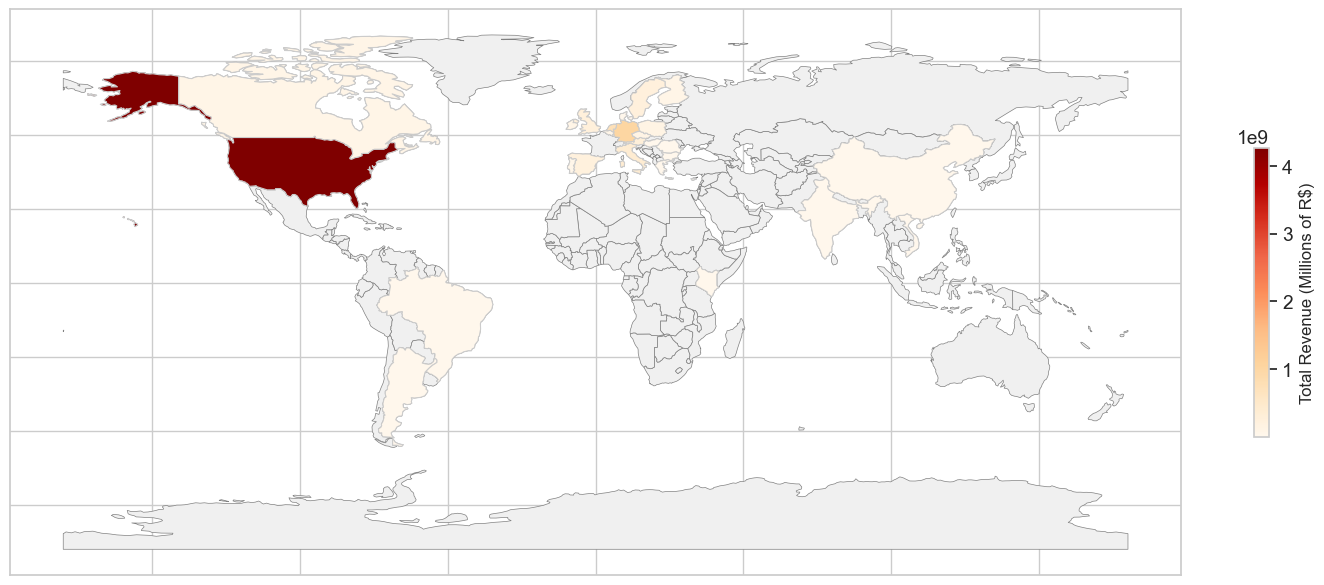

C:\Users\fsbertoglio\AppData\Local\Temp\ipykernel_7104\3320379136.py:65: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(


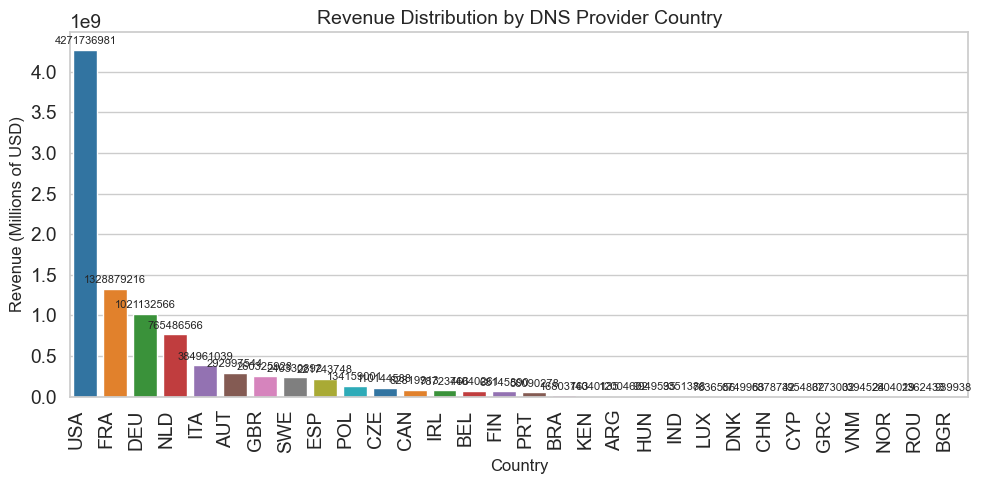

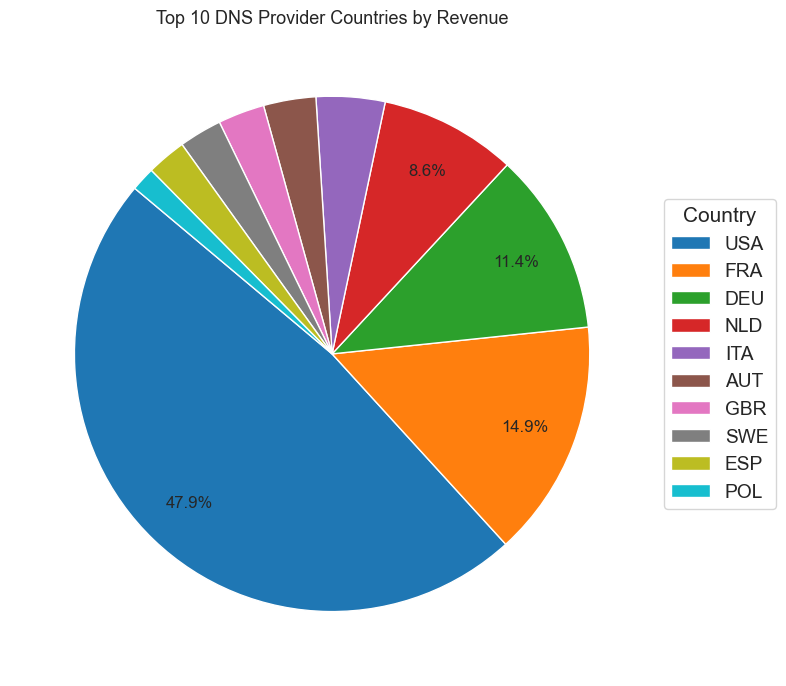

In [ ]:
import geopandas as gpd
import pandas as pd
import matplotlib.pyplot as plt
import pycountry
import seaborn as sns

def iso2_to_iso3(iso2_code):
    try:
        return pycountry.countries.get(alpha_2=iso2_code).alpha_3
    except:
        return None

# Prepare data
df = base_data.copy()
df['dominant_provider_country'] = df['dominant_provider_country'].apply(iso2_to_iso3)
df['revenue'] = df['revenue'] / 1_000  # Convert revenue to millions of R$
revenue_by_country = df.groupby('dominant_provider_country')['revenue'].sum().reset_index()

revenue_by_country = revenue_by_country.rename(columns={
    'dominant_provider_country': 'Country',
    'revenue': 'Revenue (Millions of R$)'
})
revenue_by_country = revenue_by_country.set_index('Country')
revenue_by_country.to_csv('./tables/eu_dominant_country_provider_distribution_by_revenue.csv', sep=';', encoding='utf-8')

# Read world shapefile
world = gpd.read_file(
    "https://github.com/nvkelso/natural-earth-vector/raw/master/110m_cultural/ne_110m_admin_0_countries.shp"
)
world_revenue = world.merge(
    revenue_by_country.reset_index(),
    how='left',
    left_on='ISO_A3',
    right_on='Country'
)

# Save ready-to-plot data
world_revenue.to_csv('./tables/eu_world_revenue_ready_to_plot.csv', index=False, sep=';', encoding='utf-8')

# Plot choropleth
fig, ax = plt.subplots(figsize=(15, 10))
world.plot(ax=ax, color='#f0f0f0', edgecolor='gray', linewidth=0.5)
world_revenue.plot(
    ax=ax,
    column='Revenue (Millions of R$)',
    cmap='OrRd',
    linewidth=0.8,
    edgecolor='0.8',
    legend=True,
    legend_kwds={'label': "Total Revenue (Millions of R$)", 'shrink': 0.3}
)
#ax.set_title('Geographical Origin of DNS Providers used by Brazilian Companies', fontsize=14)
ax.set_yticklabels([])
ax.set_xticklabels([])
plt.tight_layout()
plt.show()

fig.savefig(r'.\graphs\eu_geographical_origin_of_dns_providers_revenue_map.png', dpi=300, bbox_inches='tight')

# Barplot
revenue_sorted = revenue_by_country.sort_values(by='Revenue (Millions of R$)', ascending=False).reset_index()
revenue_sorted.to_csv('./tables/eu_revenue_sorted_ready_to_plot.csv', index=False, sep=';', encoding='utf-8')

plt.figure(figsize=(10, 5))
sns.barplot(
    data=revenue_sorted,
    x='Country',
    y='Revenue (Millions of R$)',
    palette='tab10'
)

for index, row in revenue_sorted.iterrows():
    plt.text(
        index, 
        row['Revenue (Millions of R$)'] + max(revenue_sorted['Revenue (Millions of R$)']) * 0.01, 
        f"{row['Revenue (Millions of R$)']:.0f}", 
        ha='center', va='bottom', fontsize=8
    )

plt.title('Revenue Distribution by DNS Provider Country', fontsize=14)
plt.xlabel('Country', fontsize=12)
plt.ylabel('Revenue (Millions of USD)', fontsize=12)
plt.xticks(rotation=90, ha='right')
plt.tight_layout()
plt.show()

# pieplot

def autopct_format(pct):
    return ('%1.1f%%' % pct) if pct > 5 else ''

revenue_top = revenue_sorted.head(10)
revenue_top.to_csv('./tables/eu_revenue_top_ready_to_plot.csv', index=False, sep=';', encoding='utf-8')

plt.figure(figsize=(8, 8))
wedges, texts, autotexts = plt.pie(
    revenue_top['Revenue (Millions of R$)'],
    autopct=autopct_format,
    startangle=140,
    colors=sns.color_palette('tab10', n_colors=len(revenue_top)),
    pctdistance=0.8,
    labeldistance=1.1
)

plt.title('Top 10 DNS Provider Countries by Revenue')
plt.legend(wedges, revenue_top['Country'], title="Country", loc="center left", bbox_to_anchor=(1, 0.5))
plt.tight_layout()
plt.show()


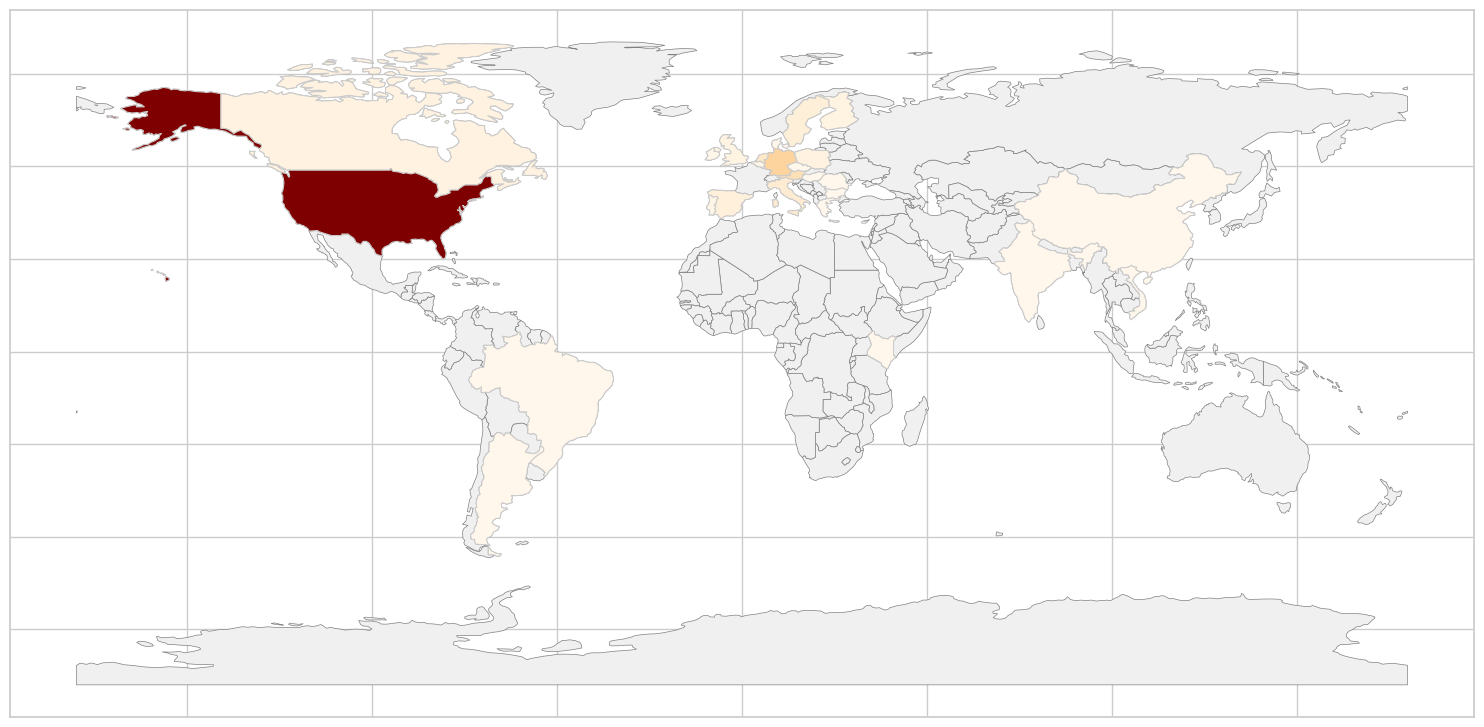

C:\Users\fsbertoglio\AppData\Local\Temp\ipykernel_7104\1008262370.py:54: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(


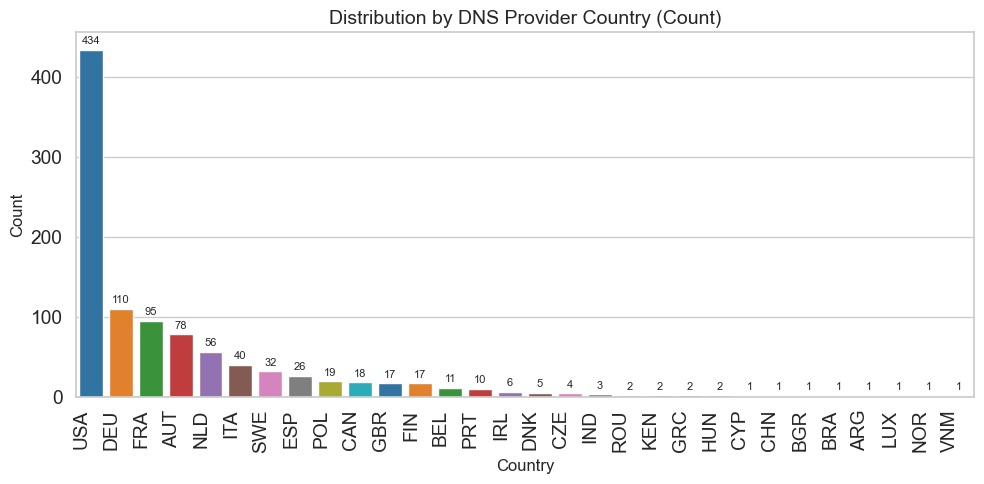

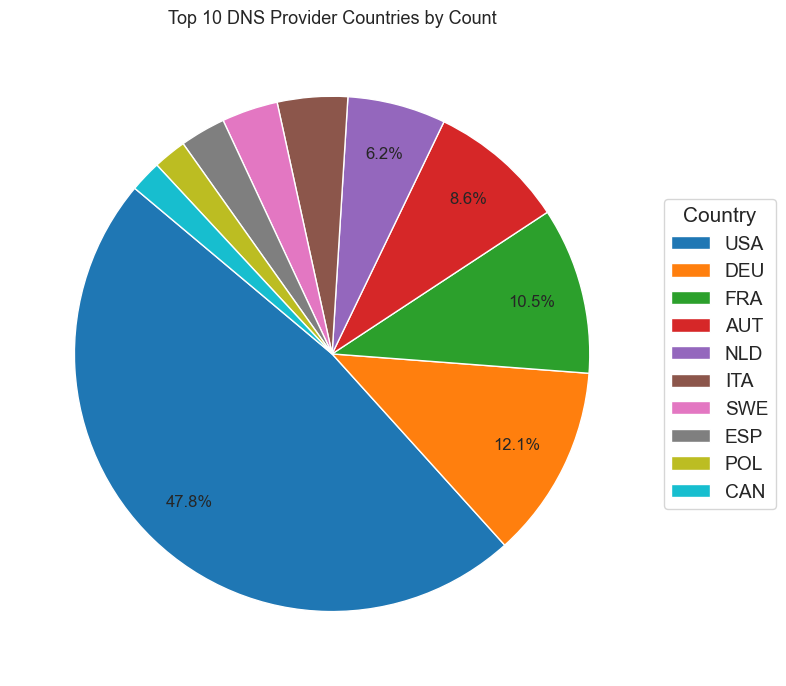

In [ ]:

import geopandas as gpd
import pandas as pd
import matplotlib.pyplot as plt
import pycountry
import seaborn as sns

# Prepare data
df = base_data.copy()
df['dominant_provider_country'] = df['dominant_provider_country'].apply(iso2_to_iso3)

# Agrupar por país e contar o número de empresas por país do provedor dominante
count_by_country = df.groupby('dominant_provider_country').size().reset_index(name='Count')

count_by_country = count_by_country.rename(columns={
    'dominant_provider_country': 'Country'
})
count_by_country = count_by_country.set_index('Country')
count_by_country.to_csv('./tables/eu_dominant_country_provider_distribution_by_count.csv', sep=';', encoding='utf-8')

# Read world shapefile
world = gpd.read_file(
    "https://github.com/nvkelso/natural-earth-vector/raw/master/110m_cultural/ne_110m_admin_0_countries.shp"
)
world_count = world.merge(
    count_by_country.reset_index(),
    how='left',
    left_on='ISO_A3',
    right_on='Country'
)

# Plot choropleth
fig, ax = plt.subplots(figsize=(15, 10))
world.plot(ax=ax, color='#f0f0f0', edgecolor='gray', linewidth=0.5)
world_count.plot(
    ax=ax,
    column='Count',
    cmap='OrRd',
    linewidth=0.8,
    edgecolor='0.8',
    legend=False,
    legend_kwds={'label': "Total Count", 'shrink': 0.3}
)
ax.set_yticklabels([])
ax.set_xticklabels([])
plt.tight_layout()
plt.show()

fig.savefig(r'.\graphs\eu_geographical_origin_of_dns_providers_count_map.png', dpi=300, bbox_inches='tight')

# Barplot
count_sorted = count_by_country.sort_values(by='Count', ascending=False).reset_index()

plt.figure(figsize=(10, 5))
sns.barplot(
    data=count_sorted,
    x='Country',
    y='Count',
    palette='tab10'
)

for index, row in count_sorted.iterrows():
    plt.text(
        index, 
        row['Count'] + max(count_sorted['Count']) * 0.01, 
        f"{int(row['Count'])}", 
        ha='center', va='bottom', fontsize=8
    )

plt.title('Distribution by DNS Provider Country (Count)', fontsize=14)
plt.xlabel('Country', fontsize=12)
plt.ylabel('Count', fontsize=12)
plt.xticks(rotation=90, ha='right')
plt.tight_layout()
plt.show()

# Pieplot
def autopct_format(pct):
    return ('%1.1f%%' % pct) if pct > 5 else ''

plt.figure(figsize=(8, 8))
count_sorted_top = count_sorted.head(10)

wedges, texts, autotexts = plt.pie(
    count_sorted_top['Count'],
    autopct=autopct_format,
    startangle=140,
    colors=sns.color_palette('tab10', n_colors=len(count_sorted_top)),
    pctdistance=0.8,
    labeldistance=1.1
)

plt.title('Top 10 DNS Provider Countries by Count')
plt.legend(wedges, count_sorted_top['Country'], title="Country", loc="center left", bbox_to_anchor=(1, 0.5))
plt.tight_layout()
plt.show()
